#### **Finite Difference Method (FDM) Baseline for 1D Buckley-Leverett Flow**

##### **Purpose:** This notebook implements a numerical Finite Difference Method (FDM) solver for the 1D Buckley-Leverett equation with capillary diffusion. It simulates the spatial-temporal distribution of wetting-phase saturation to generate the high-fidelity ground truth data required for validating the predictive accuracy and calculating the relative L2 error of the Physics-Informed Neural Network (PINN).

##### **Simulation & Grid Overview:** The simulation models two-phase immiscible fluid displacement in a 1D porous medium. The continuous domain is discretized into a rigid grid of 256 spatial nodes and 4,000 time steps. The numerical scheme utilizes a viscosity ratio of M = 2.0 and introduces a capillary diffusion coefficient of ε = 0.01 to accurately capture and stabilize the steep advection shock front traveling through the domain.

##### **Author:** Bello Oluwatobi

##### **Last Updated:** October 6, 2026

### #1 Importing libraries and Grid Initialization

In [ ]:
# importing libraries
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# specifying the physical parameters
M = 2.0          # Viscosity ratio
epsilon = 0.01   # Capillary diffusion coefficient

# specifying the grid parameters
Nx = 256         # Number of spatial points
Nt = 4000        # Number of time steps

# generating the grid
x = np.linspace(0, 1, Nx)
t = np.linspace(0, 1, Nt)
dx = x[1] - x[0]
dt = t[1] - t[0]

# initializing the Saturation matrix Sw(t, x)
Sw = np.zeros((Nt, Nx))

# setting up Boundary Condition: continuous injection of wetting phase at inlet
Sw[:, 0] = 1.0

### #2 Coding FDM Solver

In [ ]:
# writing the Explicit Forward-Time Central-Space (FTCS) method with Upwind Advection 
for i in range(0, Nt - 1):
    
    # iterating through the interior spatial nodes
    for j in range(1, Nx - 1):
        # extracting saturations for current node and neighbors at time i
        sw_curr = Sw[i, j]
        sw_prev = Sw[i, j-1]
        sw_next = Sw[i, j+1]
        
        # calculating fractional flow f(Sw) for upwind advection calculation
        f_curr = (sw_curr**2) / (sw_curr**2 + M * (1 - sw_curr)**2)
        f_prev = (sw_prev**2) / (sw_prev**2 + M * (1 - sw_prev)**2)
        
        # using the Upwind scheme for the advection term d(f(Sw))/dx
        df_dx = (f_curr - f_prev) / dx
        
        # using the Central difference for the diffusion term d2(Sw)/dx2
        d2Sw_dx2 = (sw_next - 2 * sw_curr + sw_prev) / (dx**2)
        
        # using time integration to predict saturation at time i+1
        Sw[i+1, j] = sw_curr - dt * df_dx + epsilon * dt * d2Sw_dx2
        
    # specifying the zero-flux Neumann boundary at the outlet (x=1)
    Sw[i+1, Nx-1] = Sw[i+1, Nx-2]

### #3 Visualizing the numerical solution (Ground-Truth Shock Profile)

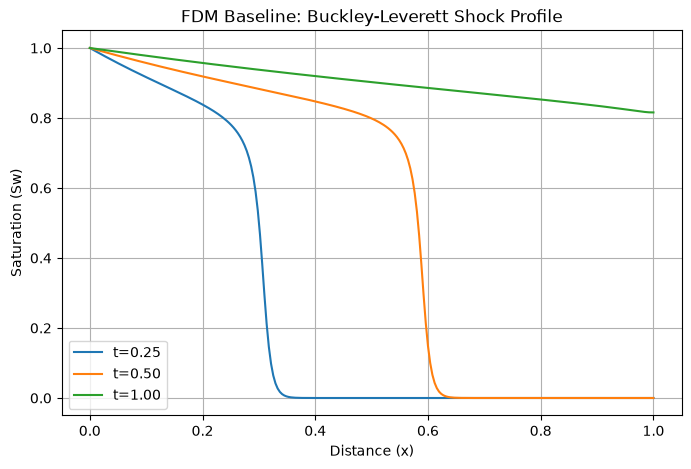

In [6]:
# plotting the shock profile at t=0.25, t=0.50, and t=1.00
plt.figure(figsize=(8, 5))
plt.plot(x, Sw[1000, :], label='t=0.25')
plt.plot(x, Sw[2000, :], label='t=0.50')
plt.plot(x, Sw[3999, :], label='t=1.00')

plt.title("FDM Baseline: Buckley-Leverett Shock Profile")
plt.xlabel("Distance (x)")
plt.ylabel("Saturation (Sw)")
plt.legend()
plt.grid(True)

plt.savefig("../results/fdm_baseline_evolution.png", dpi=300, bbox_inches="tight")

plt.show()